# 특징 1개 이용

## 1. 데이터 선택

In [11]:
# study_scores.csv 파일에서 데이터를 읽어옴
import pandas as pd

df = pd.read_csv("study_scores.csv", encoding="utf-8")

# X = df["study_hours"] # 문제 발생. 이 코드 결과가 1차원. 그런데 학습할 땐 특징이 2차원이 필요
X = df[["study_hours"]]
y = df["score"]

## 2. 사전 준비

In [12]:
# 이 예제는 필요 없음
# 결측치 처리.
# 스케일링: 범위가 다른 데이터들을 평균 0, 표준편차 1로 변환
# 원핫인코딩: 문자로 된 값을 숫자로 변환하는 방법 중
X.isna().sum() # 비어 있는 값이 있는지 확인

study_hours    0
dtype: int64

## 3. 훈련, 테스트 분리

In [13]:
from sklearn.model_selection import train_test_split

# train_test_split는 특징과 답을 이용해서 훈련 데이터와 테스트 데이터로 분리
# 리턴 값이 총 4개. 특징훈련, 특징테스트, 라벨훈련, 라벨테스트 순으로 리턴
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 4. 학습

In [15]:
from sklearn.linear_model import LinearRegression
# 어떤 모양으로 규칙을 찾을 건가를 선택(알고리즘)
# 분류 : 스팸, 스팸 아님처럼 연속되지 않은 값을 예측
# 회귀 : 성적처럼 연속된 값을 예측
model = LinearRegression() # 적절한 직선을 찾음
# 학습
model.fit(X_train, y_train)
print("학습 완료")

학습 완료


## 5. 평가

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pred_test = model.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, pred_test):.1f}점")
print(f"RMSE: {mean_squared_error(y_test, pred_test) ** 0.5:.1f}점")
print(f"R²  : {r2_score(y_test, pred_test):.2f}")
print()
print(f"학습 데이터 MAE: {mean_absolute_error(y_train, model.predict(X_train)):.1f}점")
print(f"시험 데이터 MAE: {mean_absolute_error(y_test, pred_test):.1f}점")

MAE : 5.7점
RMSE: 6.5점
R²  : 0.80

학습 데이터 MAE: 6.1점
시험 데이터 MAE: 5.7점


## 6. 예측

In [22]:
# 공부한 시간 : 0, 5, 10, 15
hours = [0, 5, 10, 15]
# 예측
preds = model.predict(pd.DataFrame({"study_hours": hours}))
# 결과를 보기 좋게 
# max(p, 0) : 음수 처리 
# min(~~, 100) : 100초과 처리 
# zip() 여러 리스트를 묶어서 반복할때 사용

# zip 이용 안함 
for i in range(len(hours)):
    h = hours[i]
    p = preds[i]
    print(f"{h:2}시간 → 모델 {p:5.1f}점 / 0~100으로 자르면 {min(max(p, 0), 100):5.1f}점")
print()    
for h, p in zip(hours, preds):
    print(f"{h:2}시간 → 모델 {p:5.1f}점 / 0~100으로 자르면 {min(max(p, 0), 100):5.1f}점")

 0시간 → 모델  30.6점 / 0~100으로 자르면  30.6점
 5시간 → 모델  56.7점 / 0~100으로 자르면  56.7점
10시간 → 모델  82.8점 / 0~100으로 자르면  82.8점
15시간 → 모델 108.9점 / 0~100으로 자르면 100.0점

 0시간 → 모델  30.6점 / 0~100으로 자르면  30.6점
 5시간 → 모델  56.7점 / 0~100으로 자르면  56.7점
10시간 → 모델  82.8점 / 0~100으로 자르면  82.8점
15시간 → 모델 108.9점 / 0~100으로 자르면 100.0점


## 7. 시각화

w: 5.22
b: 30.56


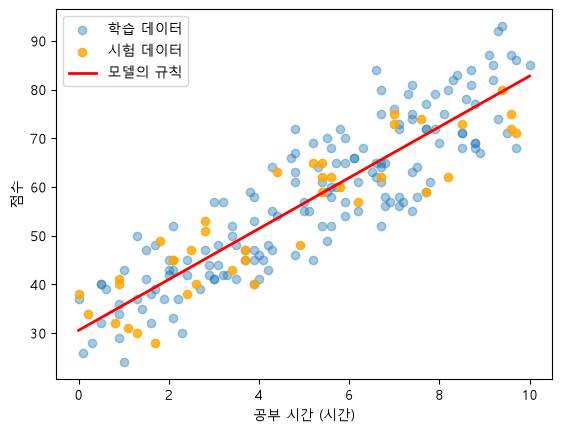

In [25]:
import platform
import matplotlib.pyplot as plt

# 그래프 한글 깨짐 방지
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 학습된 결과 : 가중치 확인
print(f"w: {model.coef_[0]:.2f}")
print(f"b: {model.intercept_:.2f}")

# 시각화
line_x = pd.DataFrame({"study_hours": [0, 10]})
line_y = model.predict(line_x)
plt.scatter(X_train["study_hours"], y_train, alpha=0.4, label="학습 데이터")
plt.scatter(X_test["study_hours"], y_test, alpha=0.8, color="orange", label="시험 데이터")
plt.plot(line_x["study_hours"], line_y, color="red", linewidth=2, label="모델의 규칙")
plt.xlabel("공부 시간 (시간)")
plt.ylabel("점수")
plt.legend()
plt.show()

# 특징 3개 이용(스케일링)

## 1. 데이터 선택

In [29]:
# 특징(X)과 라벨(y)를 선택
X = df[["study_hours", "sleep_hours", "phone_min"]] 
y = df["score"]

## 2. 사전 준비

In [35]:
from sklearn.preprocessing import StandardScaler
X # 스케일링 안한 데이터

scaler = StandardScaler()
X_s = scaler.fit_transform(X) # 스케일링 한 데이터

## 3. 훈련, 테스트 분리

In [36]:
# 스케일링 안한 데이터로 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 스케일링 한 데이터로 분리
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_s, y, test_size=0.2, random_state=42)

## 4. 학습

In [38]:
from sklearn.neighbors import KNeighborsRegressor
# 모양 선택
model2 = KNeighborsRegressor(n_neighbors=5)
model2_s = KNeighborsRegressor(n_neighbors=5)

# 학습
model2.fit(X_train, y_train)
model2_s.fit(X_train_s, y_train_s)
print("학습 완료")

학습 완료


## 5. 평가

## 6. 예측